# Student Success Assistant — Comprehensive Data Audit & EDA

This notebook is deliberately audit-first: it checks schema, `info()`, `describe()`, missingness, IDs/joins, valid ranges, date chronology, class balance, repeated attempts, correlations, and possible leakage before any modeling.

## Modeling assumption to validate
We will investigate a 14-day-after-signup prediction snapshot. The brief supplies a student-level dropout label but **no dropout timestamp**, so we cannot prove that dropout happened after the snapshot. This is a documented limitation, not something the notebook can infer away. Refund status is analyzed only as a potential leakage signal and excluded from the primary early-warning model until its timing is known.


In [25]:
from pathlib import Path
from io import StringIO
from IPython.display import display
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.max_columns",100); pd.set_option("display.width",160)
sns.set_theme(style="whitegrid")

CANDIDATES=[Path("data"),Path("../data"),Path("/mnt/data/student_success_assistant_v2/data"),Path("/mnt/data")]
DATA_DIR=next((p for p in CANDIDATES if (p/"students.csv").exists()),Path("data"))
OUT=Path("eda_outputs"); MET=OUT/"metrics"; FIG=OUT/"figures"
MET.mkdir(parents=True,exist_ok=True); FIG.mkdir(parents=True,exist_ok=True)
students_raw=pd.read_csv(DATA_DIR/"students.csv")
attempts_raw=pd.read_csv(DATA_DIR/"quiz_attempts.csv")
explanations_raw=pd.read_csv(DATA_DIR/"explanations.csv")
outcomes=pd.read_csv(DATA_DIR/"outcome.csv")
frames={"students":students_raw,"quiz_attempts":attempts_raw,"explanations":explanations_raw,"outcome":outcomes}
print("DATA_DIR:",DATA_DIR.resolve())
for n,d in frames.items(): print(f"{n:16s} {d.shape[0]:>5,} rows x {d.shape[1]} cols")


DATA_DIR: /Users/abishek/Documents/Projects/student_success_assistant/data
students           500 rows x 6 cols
quiz_attempts    2,453 rows x 6 cols
explanations       724 rows x 5 cols
outcome            500 rows x 2 cols


## 1. `df.info()`, `df.describe()`, data types and missingness

In [26]:
from io import StringIO
overview=[]
for name,df in frames.items():
    print(f"\\n===== {name}.info() =====")
    b=StringIO(); df.info(buf=b); print(b.getvalue())
    overview.append({"table":name,"rows":len(df),"columns":len(df.columns),
                     "missing_cells":int(df.isna().sum().sum()),
                     "exact_duplicate_rows":int(df.duplicated().sum()),
                     "memory_bytes":int(df.memory_usage(deep=True).sum())})
    print(f"===== {name}.describe(include='all') =====")
    display(df.describe(include="all").T)
display(pd.DataFrame(overview))


\n===== students.info() =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   student_id        500 non-null    object
 1   age_group         479 non-null    object
 2   country           500 non-null    object
 3   signup_date       500 non-null    object
 4   device            484 non-null    object
 5   refund_requested  500 non-null    object
dtypes: object(6)
memory usage: 23.6+ KB

===== students.describe(include='all') =====


,count,unique,top,freq
student_id,500,500,S001,1
age_group,479,4,18-24,214
country,500,5,India,303
signup_date,500,61,2026-07-16,18
device,484,3,mobile,269
refund_requested,500,2,no,383


\n===== quiz_attempts.info() =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2453 entries, 0 to 2452
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   attempt_id      2453 non-null   object 
 1   student_id      2453 non-null   object 
 2   lesson_id       2453 non-null   object 
 3   score           2453 non-null   int64  
 4   time_spent_min  2358 non-null   float64
 5   attempted_at    2453 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 115.1+ KB

===== quiz_attempts.describe(include='all') =====


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
attempt_id,2453,2453,A0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
student_id,2453,499,S198,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lesson_id,2453,3,L1,928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
score,2453.0,NaN,NaN,NaN,71.623318,36.437168,16.0,59.0,71.0,83.0,999.0
time_spent_min,2358.0,NaN,NaN,NaN,24.513825,9.081232,2.0,18.4,24.2,30.675,53.0
attempted_at,2453,2411,2026-07-31 10:54,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\n===== explanations.info() =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 724 entries, 0 to 723
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   explanation_id    724 non-null    object
 1   student_id        724 non-null    object
 2   lesson_id         724 non-null    object
 3   explanation_text  724 non-null    object
 4   label             60 non-null     object
dtypes: object(5)
memory usage: 28.4+ KB

===== explanations.describe(include='all') =====


,count,unique,top,freq
explanation_id,724,724,E0001,1
student_id,724,426,S281,4
lesson_id,724,3,L1,290
explanation_text,724,198,Example: mangoes in summer are cheap because s...,17
label,60,3,wrong,20


\n===== outcome.info() =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   student_id   500 non-null    object
 1   dropped_out  500 non-null    object
dtypes: object(2)
memory usage: 7.9+ KB

===== outcome.describe(include='all') =====


,count,unique,top,freq
student_id,500,500,S001,1
dropped_out,500,2,no,375


,table,rows,columns,missing_cells,exact_duplicate_rows,memory_bytes
0,students,500,6,37,0,162820
1,quiz_attempts,2453,6,95,0,586399
2,explanations,724,5,664,0,271889
3,outcome,500,2,0,0,52257


,table,column,dtype,missing_n,missing_pct,unique_nonmissing
0,explanations,label,object,664,91.712707,3
1,explanations,explanation_id,object,0,0.000000,724
2,explanations,student_id,object,0,0.000000,426
3,explanations,lesson_id,object,0,0.000000,3
4,explanations,explanation_text,object,0,0.000000,198
5,outcome,student_id,object,0,0.000000,500
6,outcome,dropped_out,object,0,0.000000,2
7,quiz_attempts,time_spent_min,float64,95,3.872809,421
8,quiz_attempts,attempt_id,object,0,0.000000,2453
9,quiz_attempts,student_id,object,0,0.000000,499


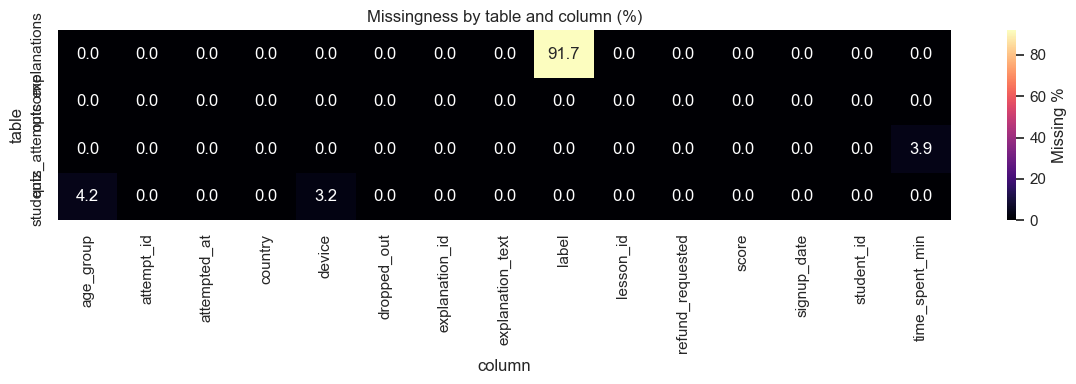

In [27]:
missing_rows=[]
for name,df in frames.items():
    for col in df.columns:
        missing_rows.append({"table":name,"column":col,"dtype":str(df[col].dtype),
            "missing_n":int(df[col].isna().sum()),"missing_pct":100*df[col].isna().mean(),
            "unique_nonmissing":int(df[col].nunique(dropna=True))})
missing=pd.DataFrame(missing_rows).sort_values(["table","missing_pct"],ascending=[True,False], ignore_index=True)
display(missing)
missing.to_csv(MET/"missingness_report.csv",index=False)
pivot=missing.pivot(index="table",columns="column",values="missing_pct").fillna(0)
fig,ax=plt.subplots(figsize=(12,4)); sns.heatmap(pivot,annot=True,fmt=".1f",cmap="magma",cbar_kws={"label":"Missing %"},ax=ax)
ax.set_title("Missingness by table and column (%)"); plt.tight_layout(); plt.savefig(FIG/"missingness_heatmap.png",dpi=160); plt.show()


## 2. Keys, duplicates and referential integrity

In [28]:
key_specs={"students":("student_id",students_raw),"outcome":("student_id",outcomes),
            "quiz_attempts":("attempt_id",attempts_raw),"explanations":("explanation_id",explanations_raw)}
key_rows=[]
for name,(key,df) in key_specs.items():
    key_rows.append({"table":name,"key":key,"missing_key":int(df[key].isna().sum()),
        "duplicate_key_rows":int(df[key].duplicated(keep=False).sum()),
        "unique_keys":int(df[key].nunique()),"rows":len(df),"key_unique":df[key].is_unique})
display(pd.DataFrame(key_rows))
student_ids=set(students_raw.student_id.dropna())
integrity=pd.DataFrame([
 {"check":"outcomes IDs exist in students","violations":len(set(outcomes.student_id)-student_ids)},
 {"check":"quiz student IDs exist in students","violations":len(set(attempts_raw.student_id)-student_ids)},
 {"check":"explanation student IDs exist in students","violations":len(set(explanations_raw.student_id)-student_ids)},
 {"check":"students without outcomes","violations":len(student_ids-set(outcomes.student_id))},
 {"check":"students without quiz attempts","violations":len(student_ids-set(attempts_raw.student_id))},
 {"check":"students without explanations","violations":len(student_ids-set(explanations_raw.student_id))}
])
display(integrity); integrity.to_csv(MET/"referential_integrity.csv",index=False)
print("Caution: do not join the raw quiz and explanation tables together before aggregation; one-to-many joins multiply rows.")


,table,key,missing_key,duplicate_key_rows,unique_keys,rows,key_unique
0,students,student_id,0,0,500,500,True
1,outcome,student_id,0,0,500,500,True
2,quiz_attempts,attempt_id,0,0,2453,2453,True
3,explanations,explanation_id,0,0,724,724,True


,check,violations
0,outcomes IDs exist in students,0
1,quiz student IDs exist in students,0
2,explanation student IDs exist in students,0
3,students without outcomes,0
4,students without quiz attempts,1
5,students without explanations,74


Caution: do not join the raw quiz and explanation tables together before aggregation; one-to-many joins multiply rows.


## 3. Date ranges, course-window checks and event chronology

,table,field,min,max,unparseable
0,students,signup_date,2026-06-01 00:00:00,2026-07-31 00:00:00,0
1,quiz_attempts,attempted_at,2026-06-02 12:41:00,2026-09-28 14:00:00,0


Course window per brief: 2026-06-01 00:00:00 to 2026-09-30 23:59:59
Signup dates outside course window: 0
Quiz attempts outside course window: 0
Attempts before signup date: 0


,attempt_id,student_id,lesson_id,score,time_spent_min,attempted_at,attempt_dt,signup_dt,days_from_signup


,days_from_signup
count,2453.000000
mean,25.432532
std,19.839569
min,0.000000
1%,0.000000
5%,2.000000
25%,9.000000
50%,21.000000
75%,38.000000
95%,64.000000


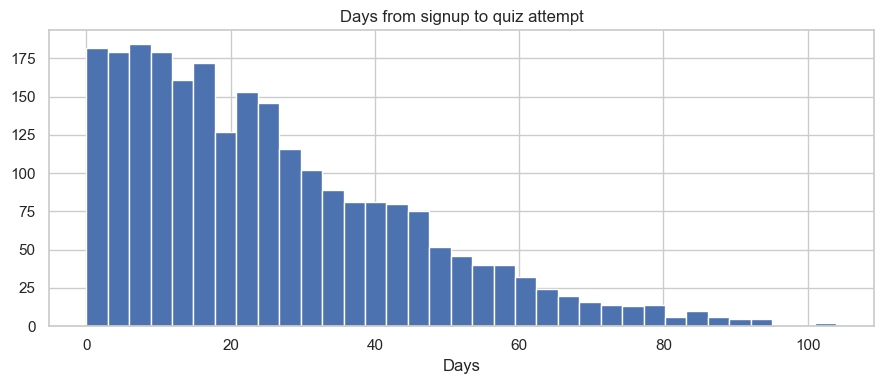

In [29]:
students=students_raw.copy(); attempts=attempts_raw.copy()
students["signup_dt"]=pd.to_datetime(students.signup_date,errors="coerce")
attempts["attempt_dt"]=pd.to_datetime(attempts.attempted_at,errors="coerce")
date_report=pd.DataFrame([
 {"table":"students","field":"signup_date","min":students.signup_dt.min(),"max":students.signup_dt.max(),"unparseable":int(students.signup_dt.isna().sum())},
 {"table":"quiz_attempts","field":"attempted_at","min":attempts.attempt_dt.min(),"max":attempts.attempt_dt.max(),"unparseable":int(attempts.attempt_dt.isna().sum())}
])
display(date_report); date_report.to_csv(MET/"date_ranges.csv",index=False)
COURSE_START=pd.Timestamp("2026-06-01"); COURSE_END=pd.Timestamp("2026-09-30 23:59:59")
print("Course window per brief:",COURSE_START,"to",COURSE_END)
print("Signup dates outside course window:",int(((students.signup_dt<COURSE_START)|(students.signup_dt>COURSE_END)).sum()))
print("Quiz attempts outside course window:",int(((attempts.attempt_dt<COURSE_START)|(attempts.attempt_dt>COURSE_END)).sum()))
signup=students.set_index("student_id").signup_dt
attempts["signup_dt"]=attempts.student_id.map(signup)
attempts["days_from_signup"]=(attempts.attempt_dt.dt.normalize()-attempts.signup_dt.dt.normalize()).dt.days
pre=attempts[attempts.days_from_signup<0]
print("Attempts before signup date:",len(pre)); display(pre.head(20))
display(attempts.days_from_signup.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).to_frame())
fig,ax=plt.subplots(figsize=(9,4)); ax.hist(attempts.days_from_signup.dropna(),bins=35)
ax.set_title("Days from signup to quiz attempt"); ax.set_xlabel("Days"); plt.tight_layout(); plt.savefig(FIG/"days_from_signup.png",dpi=160); plt.show()


## 4. Numeric range checks: scores and durations

Invalid/missing/out-of-range scores: 3


,attempt_id,student_id,lesson_id,score,attempt_dt,days_from_signup
240,A0241,S039,L2,999,2026-07-10 08:10:00,22
335,A0336,S332,L3,999,2026-09-11 12:29:00,51
2434,A2435,S194,L2,999,2026-07-07 18:42:00,25


Missing or negative durations: 95


,attempt_id,student_id,lesson_id,time_spent_min,attempt_dt
98,A0099,S326,L3,NaN,2026-08-15 23:33:00
106,A0107,S073,L3,NaN,2026-08-05 06:32:00
144,A0145,S491,L1,NaN,2026-06-19 01:18:00
151,A0152,S384,L2,NaN,2026-08-20 03:57:00
155,A0156,S084,L2,NaN,2026-08-01 15:13:00
272,A0273,S216,L1,NaN,2026-06-23 09:37:00
315,A0316,S012,L2,NaN,2026-08-06 23:44:00
424,A0425,S040,L2,NaN,2026-07-19 04:11:00
434,A0435,S424,L1,NaN,2026-06-24 16:41:00
482,A0483,S094,L2,NaN,2026-06-28 02:12:00


Score describe including invalid values:


,score_num
count,2453.000000
mean,71.623318
std,36.437168
min,16.000000
1%,32.000000
5%,43.000000
25%,59.000000
50%,71.000000
75%,83.000000
95%,99.000000


Duration describe for observed nonnegative values:


,duration_num
count,2358.000000
mean,24.513825
std,9.081232
min,2.000000
1%,3.357000
5%,9.600000
25%,18.400000
50%,24.200000
75%,30.675000
95%,39.400000


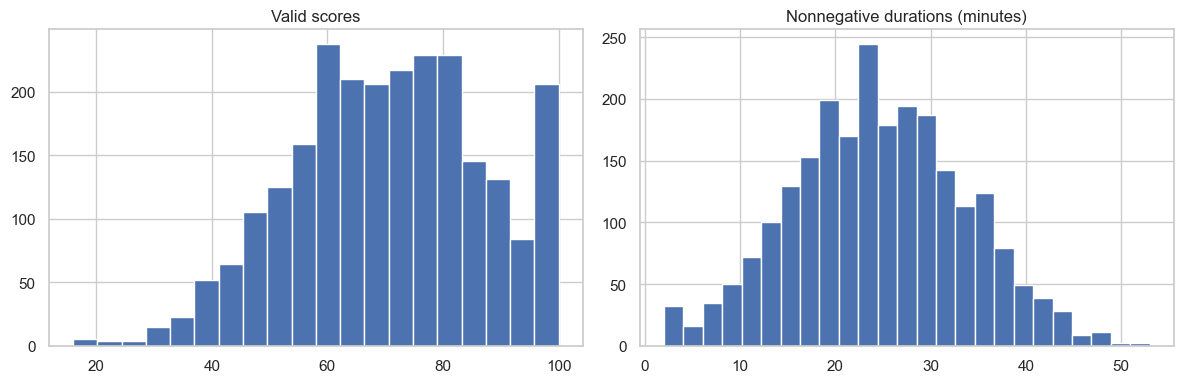

In [30]:
attempts["score_num"]=pd.to_numeric(attempts.score,errors="coerce")
attempts["duration_num"]=pd.to_numeric(attempts.time_spent_min,errors="coerce")
invalid_score=attempts[attempts.score_num.isna()|~attempts.score_num.between(0,100)]
invalid_duration=attempts[attempts.duration_num.isna()|(attempts.duration_num<0)]
print("Invalid/missing/out-of-range scores:",len(invalid_score))
display(invalid_score[["attempt_id","student_id","lesson_id","score","attempt_dt","days_from_signup"]])
print("Missing or negative durations:",len(invalid_duration))
display(invalid_duration[["attempt_id","student_id","lesson_id","time_spent_min","attempt_dt"]].head(30))
print("Score describe including invalid values:"); display(attempts.score_num.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).to_frame())
print("Duration describe for observed nonnegative values:"); display(attempts.loc[attempts.duration_num>=0,"duration_num"].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).to_frame())
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(attempts.loc[attempts.score_num.between(0,100),"score_num"],bins=20); axes[0].set_title("Valid scores")
axes[1].hist(attempts.loc[attempts.duration_num>=0,"duration_num"],bins=25); axes[1].set_title("Nonnegative durations (minutes)")
plt.tight_layout(); plt.savefig(FIG/"score_duration_distributions.png",dpi=160); plt.show()


### Cleaning decision: invalid scores and durations

- **Scores outside 0–100:** exclude from score aggregates. Do not clip 999 to 100 because that fabricates a perfect score. Keep the attempt row for event counts if its ID/timestamp are otherwise valid, and retain an invalid-score flag/count for audit.
- **Missing duration:** preserve the attempt; aggregate duration over observed values and optionally add missing-duration count/rate. Do not invent a duration without justification.
- **Negative duration:** physically implausible; exclude from duration aggregates and inspect.
- **Long but nonnegative duration:** flag for review, not automatic removal. The task supplies no maximum plausible duration.
- **Missing student attributes:** keep the student; impute/encode missing values inside the training pipeline, fitted on training data only.
- **Missing target:** do not impute labels for supervised training. Investigate or exclude only from labeled training.


## 5. Categorical domains, label validity and text checks

In [31]:
for name,df in frames.items():
    print(f"\\n===== {name}: object-column value counts =====")
    for col in df.select_dtypes(include=["object","string"]).columns:
        print(f"-- {col}; unique including NA={df[col].nunique(dropna=False)}")
        display(df[col].value_counts(dropna=False).head(40).to_frame("count"))
print("Unexpected dropout labels:",sorted(set(outcomes.dropped_out.dropna().astype(str).str.strip().str.lower())-{"yes","no"}))
print("Unexpected explanation labels:",sorted(set(explanations_raw.label.dropna().astype(str).str.strip().str.lower())-{"understood","partial","wrong"}))
print("Attempt lesson IDs:",sorted(attempts_raw.lesson_id.dropna().astype(str).unique()))
print("Explanation lesson IDs:",sorted(explanations_raw.lesson_id.dropna().astype(str).unique()))
display(pd.DataFrame([
 {"field":"explanation_text","nulls":int(explanations_raw.explanation_text.isna().sum()),"blank_or_whitespace":int(explanations_raw.explanation_text.fillna("").astype(str).str.strip().eq("").sum())},
 {"field":"label","nulls":int(explanations_raw.label.isna().sum()),"blank_or_whitespace":int(explanations_raw.label.fillna("").astype(str).str.strip().eq("").sum())}
]))


\n===== students: object-column value counts =====
-- student_id; unique including NA=500


,count
student_id,
S001,1
S330,1
S343,1
S342,1
S341,1
S340,1
S339,1
S338,1
S337,1


-- age_group; unique including NA=5


,count
age_group,
18-24,214
25-34,152
35-44,77
45+,36
NaN,21


-- country; unique including NA=5


...

,count
student_id,
S001,1
S330,1
S343,1
S342,1
S341,1
S340,1
S339,1
S338,1
S337,1


-- dropped_out; unique including NA=2


,count
dropped_out,
no,375
yes,125


Unexpected dropout labels: []
Unexpected explanation labels: []
Attempt lesson IDs: ['L1', 'L2', 'L3']
Explanation lesson IDs: ['L1', 'L2', 'L3']


,field,nulls,blank_or_whitespace
0,explanation_text,0,0
1,label,664,664


## 6. Outcome balance and refund feature leakage investigation

,students
dropped_out,
no,375
yes,125


Dropout rate: 0.25
Majority-class accuracy baseline: 0.75


,count,dropout_rate
refund_clean,,
no,383,0.049608
yes,117,0.905983


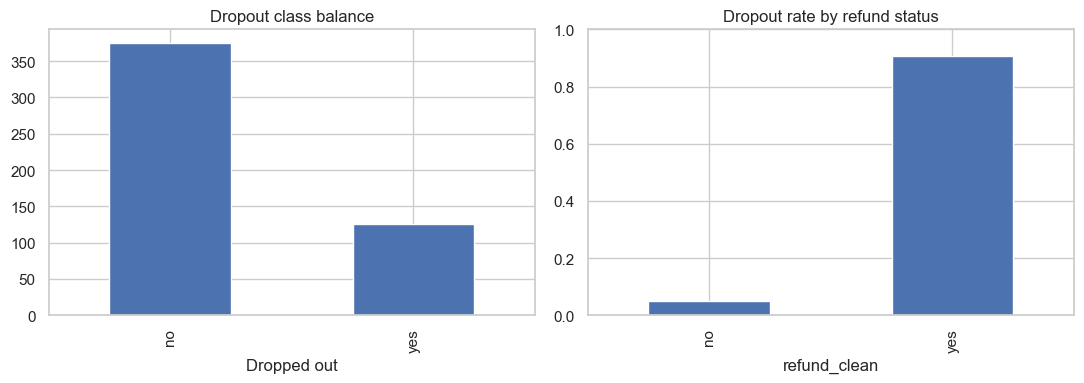

In [32]:
so=students_raw.merge(outcomes,on="student_id",how="left",validate="one_to_one")
so["dropout"]=so.dropped_out.astype("string").str.strip().str.lower().map({"yes":1,"no":0})
so["refund_clean"]=so.refund_requested.astype("string").str.strip().str.lower()
display(so.dropped_out.value_counts(dropna=False).to_frame("students"))
print("Dropout rate:",so.dropout.mean())
print("Majority-class accuracy baseline:",so.dropped_out.value_counts(normalize=True).max())
refund_summary=so.groupby("refund_clean",dropna=False).dropout.agg(["count","mean"]).rename(columns={"mean":"dropout_rate"})
display(refund_summary); refund_summary.to_csv(MET/"dropout_by_refund.csv")
fig,axes=plt.subplots(1,2,figsize=(11,4))
so.dropped_out.value_counts().reindex(["no","yes"],fill_value=0).plot(kind="bar",ax=axes[0]); axes[0].set_title("Dropout class balance"); axes[0].set_xlabel("Dropped out")
refund_summary.dropout_rate.plot(kind="bar",ax=axes[1]); axes[1].set_title("Dropout rate by refund status"); axes[1].set_ylim(0,1)
plt.tight_layout(); plt.savefig(FIG/"outcome_refund_analysis.png",dpi=160); plt.show()


Refund status has a strong association with the target in this dataset. That is not proof of causation, and without a timestamp we cannot know whether it was available before the student was at risk. Exclude it from the primary early-warning model. If useful, report a clearly labelled leakage diagnostic/ablation, not the headline model result.

## 7. Repeated attempts, per-lesson performance and recency-weighted features

Attempts/student distribution:


,attempt_count
count,499.000000
mean,4.915832
std,1.965805
min,1.000000
50%,5.000000
75%,6.000000
90%,7.200000
95%,8.000000
99%,9.000000
max,10.000000


Repeated student-lesson pairs: 827


,,attempts_per_student_lesson
student_id,lesson_id,
S097,L2,4
S363,L1,4
S198,L2,4
S040,L2,4
S050,L1,4
S213,L2,4
S001,L1,3
S381,L2,3
S198,L3,3


,count,mean,median,std,min,max
lesson_id,,,,,,
L1,928,69.539871,69.0,16.841495,16,100
L2,850,71.316471,72.0,16.110626,19,100
L3,672,70.748512,71.0,16.713796,31,100


,score_num,duration_num,days_from_signup
score_num,1.000000,0.046382,0.051919
duration_num,0.046382,1.000000,0.068777
days_from_signup,0.051919,0.068777,1.000000


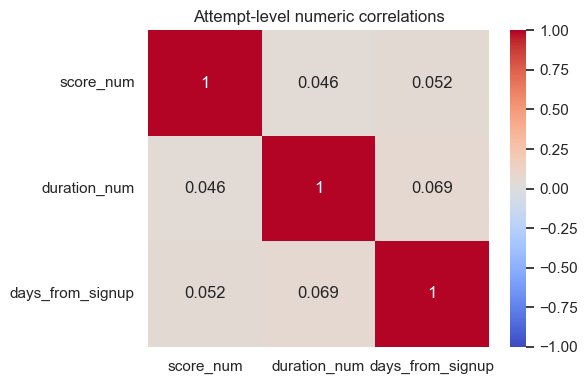

,valid_score_count,recency_weighted_score
student_id,,
S001,3,85.897395
S002,7,55.232625
S003,6,72.318183
S004,3,61.816432
S005,7,60.290580


In [33]:
valid=attempts[attempts.score_num.between(0,100)].copy().sort_values(["student_id","lesson_id","attempt_dt"])
per_student=attempts.groupby("student_id").size().rename("attempt_count")
per_pair=attempts.groupby(["student_id","lesson_id"]).size().rename("attempts_per_student_lesson")
print("Attempts/student distribution:"); display(per_student.describe(percentiles=[.5,.75,.9,.95,.99]).to_frame())
print("Repeated student-lesson pairs:",int((per_pair>1).sum())); display(per_pair[per_pair>1].sort_values(ascending=False).head(20).to_frame())
lesson_scores=valid.groupby("lesson_id").score_num.agg(["count","mean","median","std","min","max"])
display(lesson_scores); lesson_scores.to_csv(MET/"score_summary_by_lesson.csv")
# Numeric correlations among valid attempt records; descriptive, not causal.
corr_attempt=valid[["score_num","duration_num","days_from_signup"]].corr(numeric_only=True)
display(corr_attempt)
fig,ax=plt.subplots(figsize=(6,4)); sns.heatmap(corr_attempt,annot=True,vmin=-1,vmax=1,center=0,cmap="coolwarm",ax=ax)
ax.set_title("Attempt-level numeric correlations"); plt.tight_layout(); plt.savefig(FIG/"attempt_correlation.png",dpi=160); plt.show()
# Example recency-weighted score relative to each student's latest observed valid attempt.
# For the actual model, replace latest-observed time with that student's snapshot cutoff.
HALF_LIFE_DAYS=14
valid["age_days_from_latest"]=(valid.groupby("student_id").attempt_dt.transform("max")-valid.attempt_dt).dt.total_seconds()/86400
valid["recency_weight"]=np.exp(-np.log(2)*valid.age_days_from_latest/HALF_LIFE_DAYS)
valid["weighted_score"]=valid.score_num*valid.recency_weight
weighted=valid.groupby("student_id").agg(weighted_sum=("weighted_score","sum"),weight_sum=("recency_weight","sum"),valid_score_count=("score_num","count"))
weighted["recency_weighted_score"]=weighted.weighted_sum/weighted.weight_sum
display(weighted[["valid_score_count","recency_weighted_score"]].head())


### Weighted average: useful idea, but not a cleaning rule

A recency-weighted score can represent current performance better than a plain mean when students have repeated attempts. For example, exponential decay with a 14-day half-life gives newer attempts more influence. This is **not reinforcement learning**; it is a feature summarizing a history.

Do not replace all other features with it. Compare mean score, latest score, score trend, weighted score, attempt count, and lesson-specific performance. Keep the snapshot cutoff fixed: using a student's latest *overall* attempt for a 14-day prediction would leak future information. Also avoid pooling different lessons blindly if lesson difficulty differs.


## 8. Outcome comparisons and weekly activity

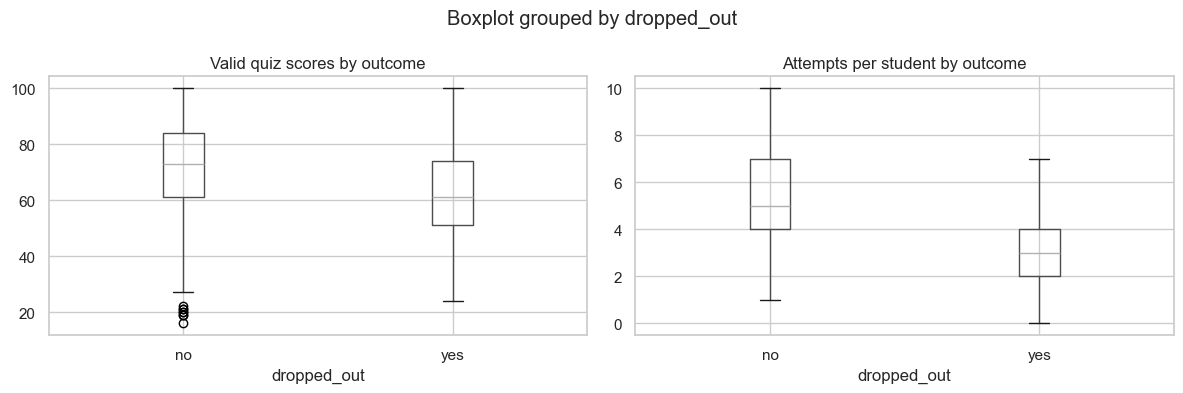

,count,mean,median,std
dropped_out,,,,
no,2057,71.959164,73.0,16.250330
yes,393,62.786260,61.0,16.091261


attempt_count              lesson_count             
                     mean median count         mean median count
dropped_out                                                     
no               5.490667    5.0   375     2.682667    3.0   375
yes              3.152000    3.0   125     2.056000    2.0   125

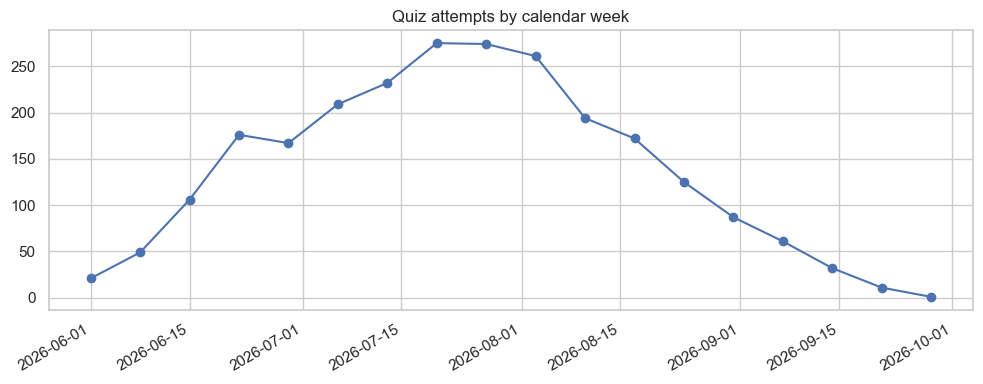

,week,attempts
0,2026-06-01,21
1,2026-06-08,49
2,2026-06-15,106
3,2026-06-22,176
4,2026-06-29,167
5,2026-07-06,209
6,2026-07-13,232
7,2026-07-20,275
8,2026-07-27,274
9,2026-08-03,261


In [34]:
valid_outcome=valid.merge(outcomes[["student_id","dropped_out"]],on="student_id",how="left",validate="many_to_one")
attempt_counts=attempts.groupby("student_id").size().rename("attempt_count")
lesson_counts=attempts.groupby("student_id").lesson_id.nunique().rename("lesson_count")
eng=students_raw[["student_id"]].merge(outcomes,on="student_id",validate="one_to_one").join(attempt_counts,on="student_id").join(lesson_counts,on="student_id")
eng[["attempt_count","lesson_count"]]=eng[["attempt_count","lesson_count"]].fillna(0)
fig,axes=plt.subplots(1,2,figsize=(12,4))
valid_outcome.boxplot(column="score_num",by="dropped_out",ax=axes[0]); axes[0].set_title("Valid quiz scores by outcome")
eng.boxplot(column="attempt_count",by="dropped_out",ax=axes[1]); axes[1].set_title("Attempts per student by outcome")
plt.tight_layout(); plt.savefig(FIG/"outcome_performance_engagement.png",dpi=160); plt.show()
display(valid_outcome.groupby("dropped_out").score_num.agg(["count","mean","median","std"]))
display(eng.groupby("dropped_out")[["attempt_count","lesson_count"]].agg(["mean","median","count"]))
weekly=attempts.dropna(subset=["attempt_dt"]).assign(week=lambda d:d.attempt_dt.dt.to_period("W").dt.start_time).groupby("week").size().rename("attempts").reset_index()
fig,ax=plt.subplots(figsize=(10,4)); ax.plot(weekly["week"],weekly["attempts"],marker="o")
ax.set_title("Quiz attempts by calendar week"); plt.xticks(rotation=30,ha="right"); plt.tight_layout(); plt.savefig(FIG/"weekly_attempts.png",dpi=160); plt.show()
display(weekly)


## 9. Student-level correlation matrix (EDA only)

,dropout_binary,attempt_count,valid_score_count,mean_score_alltime,latest_score_alltime,mean_duration,distinct_lessons,missing_duration_count
dropout_binary,1.000000,-0.509030,-0.510364,-0.362785,-0.247702,-0.362620,-0.418254,-0.128976
attempt_count,-0.509030,1.000000,0.999225,0.279788,0.190075,0.194070,0.740327,0.171149
valid_score_count,-0.510364,0.999225,1.000000,0.278364,0.187737,0.194528,0.740732,0.167896
mean_score_alltime,-0.362785,0.279788,0.278364,1.000000,0.684532,0.202669,0.165675,0.081083
latest_score_alltime,-0.247702,0.190075,0.187737,0.684532,1.000000,0.166615,0.122652,0.071302
mean_duration,-0.362620,0.194070,0.194528,0.202669,0.166615,1.000000,0.214410,0.097599
distinct_lessons,-0.418254,0.740327,0.740732,0.165675,0.122652,0.214410,1.000000,0.110832
missing_duration_count,-0.128976,0.171149,0.167896,0.081083,0.071302,0.097599,0.110832,1.000000


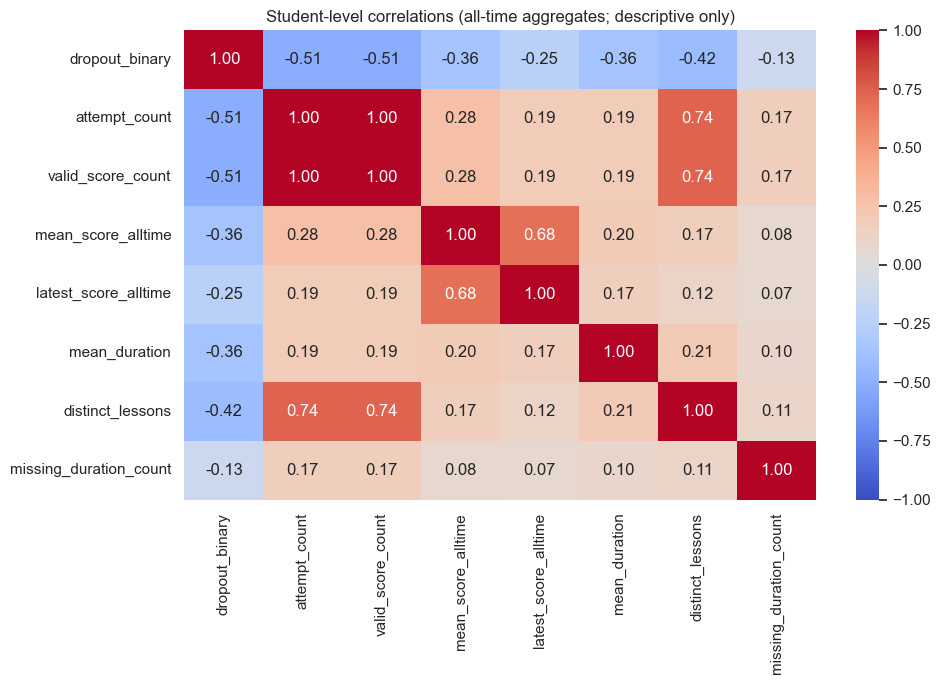

In [35]:
# All-time aggregates are useful for exploring relationships but are NOT leakage-safe early-warning features.
agg=attempts.assign(valid_score=attempts.score_num.where(attempts.score_num.between(0,100))).groupby("student_id").agg(
 attempt_count=("attempt_id","count"),valid_score_count=("valid_score","count"),
 mean_score_alltime=("valid_score","mean"),latest_score_alltime=("valid_score","last"),
 mean_duration=("duration_num","mean"),distinct_lessons=("lesson_id","nunique"),
 missing_duration_count=("duration_num",lambda s:int(s.isna().sum()))).reset_index()
sc=students_raw[["student_id"]].merge(outcomes,on="student_id",validate="one_to_one").merge(agg,on="student_id",how="left",validate="one_to_one")
sc["dropout_binary"]=sc.dropped_out.map({"yes":1,"no":0})
num=["dropout_binary","attempt_count","valid_score_count","mean_score_alltime","latest_score_alltime","mean_duration","distinct_lessons","missing_duration_count"]
cm=sc[num].corr(numeric_only=True); display(cm)
fig,ax=plt.subplots(figsize=(10,7)); sns.heatmap(cm,annot=True,fmt=".2f",vmin=-1,vmax=1,center=0,cmap="coolwarm",ax=ax)
ax.set_title("Student-level correlations (all-time aggregates; descriptive only)")
plt.tight_layout(); plt.savefig(FIG/"student_correlations.png",dpi=160); plt.show()
print("WARNING: all-time aggregates include events after a possible early snapshot. Do not use them as final training features.")


## 10. Cleaning decisions and modeling contract

| Problem | Decision | Reason |
|---|---|---|
| Invalid score outside 0–100 | Exclude from score aggregates; retain attempt count and invalid-score flag | Do not convert 999 into 100 |
| Missing duration | Keep attempt; skip missing duration in aggregates; optionally add missingness feature | Event and score can still be valid |
| Negative duration | Exclude from duration aggregates and investigate | Physically implausible |
| Long positive duration | Flag for review; no arbitrary cap | No domain limit supplied |
| Missing age/device | Preserve row; impute/encode inside training pipeline | Avoid dropping students |
| Missing outcome | Investigate; do not impute target | Supervised label required |
| Duplicate primary key | Stop and inspect | Could be conflicting records |
| Students without attempts | Keep; set counts to zero | No activity may be a risk signal |
| Students without explanations | Keep; mark explanation unavailable | Do not invent learning state |
| Pre-signup attempts | Investigate; exclude from snapshot features | Chronologically inconsistent |
| Events after cutoff | Exclude from early-warning features | Prevent temporal leakage |
| Refund status | Exclude from primary model until timing is known | Potential post-decision signal |
| Demographic fields | Assess fairness and utility; avoid automatic inclusion | May encode structural disadvantage |
| Invalid LLM output | Schema validate; retry or log failure/abstain | Never silently trust malformed output |

### Feature contract for downstream `features.py`

At each student's snapshot `signup_date + 14 days`:
1. Include only attempts on/after signup and at/before snapshot.
2. Use valid scores for score aggregates, but count eligible attempts separately.
3. Calculate mean, latest, trend and recency-weighted score using only eligible attempts.
4. Prefer per-lesson features where practical.
5. Include no-attempt/no-valid-score flags.
6. Do not use explanation contents or labels as temporal features because the explanations table has no submission timestamp.
7. Exclude refund status unless timing is verified.
8. Left-join aggregates and assert exactly one row per student.
9. Fit preprocessing only on training data.
10. Keep test data untouched until final evaluation.

**Key limitation:** `outcome.csv` contains no dropout timestamp. We can enforce feature-time cutoffs, but cannot prove the target occurs after the cutoff. Document this as an assumption in README and research memo.


In [36]:
# Export compact audit artifacts for reproducibility.
pd.DataFrame(overview).to_csv(MET/"table_overview.csv",index=False)
date_report.to_csv(MET/"date_ranges.csv",index=False)
integrity.to_csv(MET/"referential_integrity.csv",index=False)
invalid_score.to_csv(MET/"invalid_score_rows.csv",index=False)
invalid_duration.to_csv(MET/"missing_or_invalid_duration_rows.csv",index=False)
cm.to_csv(MET/"student_correlations.csv")
weekly.to_csv(MET/"weekly_attempt_counts.csv",index=False)
print("Audit tables:",MET.resolve())
print("Figures:",FIG.resolve())


Audit tables: /Users/abishek/Documents/Projects/student_success_assistant/notebooks/eda_outputs/metrics
Figures: /Users/abishek/Documents/Projects/student_success_assistant/notebooks/eda_outputs/figures
